# Proyecto final · Olist: del pedido a la reseña

**Equipo:** Leonardo Isai Zepeda Tolentino

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.

In [1]:
import warnings
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
CLAVE = getpass("Contraseña: ")
motor = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(CLAVE)}@{HOST}:5432/postgres", poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

Contraseña: ··········


,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [2]:
# TU CÓDIGO AQUÍ

# Consulta SQL para construir la tabla del contrato
# Una fila final representa un pedido entregado y con reseña.

consulta = """
WITH items_resumen AS (
    SELECT
        oi.order_id,
        COUNT(*) AS n_items,
        COUNT(DISTINCT oi.seller_id) AS n_vendedores,
        SUM(oi.price) AS precio_total,
        SUM(oi.freight_value) AS flete_total,
        SUM(p.product_weight_g) AS peso_total_g,
        AVG(p.product_photos_qty) AS fotos_promedio
    FROM final.order_items AS oi
    LEFT JOIN final.products AS p
        ON oi.product_id = p.product_id
    GROUP BY oi.order_id
),

articulo_1 AS (
    SELECT
        oi.order_id,
        p.product_category_name AS categoria,
        s.seller_state AS estado_vendedor
    FROM final.order_items AS oi
    LEFT JOIN final.products AS p
        ON oi.product_id = p.product_id
    LEFT JOIN final.sellers AS s
        ON oi.seller_id = s.seller_id
    WHERE oi.order_item_id = 1
),

pago_principal AS (
    SELECT DISTINCT ON (op.order_id)
        op.order_id,
        op.payment_type AS tipo_pago
    FROM final.order_payments AS op
    ORDER BY
        op.order_id,
        op.payment_value DESC,
        op.payment_sequential ASC
),

pagos_resumen AS (
    SELECT
        order_id,
        MAX(payment_installments) AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
),

resena_reciente AS (
    SELECT DISTINCT ON (r.order_id)
        r.order_id,
        r.review_score
    FROM final.order_reviews AS r
    ORDER BY
        r.order_id,
        r.review_answer_timestamp DESC NULLS LAST
)

SELECT
    o.order_id,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state AS estado_cliente,
    ir.n_items,
    ir.n_vendedores,
    ir.precio_total,
    ir.flete_total,
    ir.peso_total_g,
    ir.fotos_promedio,
    a1.categoria,
    a1.estado_vendedor,
    pp.tipo_pago,
    pr.cuotas_max,
    CASE
        WHEN rr.review_score IN (1, 2) THEN 1
        ELSE 0
    END AS mala_resena

FROM final.orders AS o

INNER JOIN final.customers AS c
    ON o.customer_id = c.customer_id

INNER JOIN resena_reciente AS rr
    ON o.order_id = rr.order_id

LEFT JOIN items_resumen AS ir
    ON o.order_id = ir.order_id

LEFT JOIN articulo_1 AS a1
    ON o.order_id = a1.order_id

LEFT JOIN pago_principal AS pp
    ON o.order_id = pp.order_id

LEFT JOIN pagos_resumen AS pr
    ON o.order_id = pr.order_id

WHERE
    o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL

ORDER BY o.order_purchase_timestamp;
"""

pedidos = pd.read_sql(consulta, motor)

print("Dimensiones:", pedidos.shape)
print("Número de pedidos:", len(pedidos))
print("Número de columnas:", len(pedidos.columns))

pedidos.head()

Dimensiones: (77304, 18)
Número de pedidos: 77304
Número de columnas: 18


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,SP,3,1,134.97,8.49,3000.0,1.0,beleza_saude,PR,None,NaN,1
1,3b697a20d9e427646d92567910af6d57,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,SP,1,1,29.90,15.56,300.0,3.0,relogios_presentes,PR,boleto,1.0,0
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,RS,1,1,21.90,17.19,400.0,1.0,esporte_lazer,SP,boleto,1.0,0
3,a41c8759fbe7aab36ea07e038b2d4465,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,RS,1,1,36.49,17.24,767.0,1.0,esporte_lazer,SP,boleto,1.0,0
4,d207cc272675637bfed0062edffd0818,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,SP,1,1,119.90,13.56,2050.0,1.0,moveis_decoracao,SP,credit_card,6.0,1


Esta celda verifica el contrato. Debe imprimir `True`:

In [3]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77304 pedidos


In [4]:
# Revisión de faltantes y valores raros

resumen_faltantes = pd.DataFrame({
    "faltantes": pedidos.isna().sum(),
    "porcentaje": (pedidos.isna().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)

display(resumen_faltantes)

print("\nValores objetivo:")
print(pedidos["mala_resena"].value_counts(dropna=False))

print("\nDistribución porcentual de mala reseña:")
print((pedidos["mala_resena"].value_counts(normalize=True) * 100).round(2))

print("\nValores numéricos principales:")
display(
    pedidos[
        [
            "n_items",
            "n_vendedores",
            "precio_total",
            "flete_total",
            "peso_total_g",
            "fotos_promedio",
            "cuotas_max",
        ]
    ].describe().T
)

,faltantes,porcentaje
categoria,1263,1.63
fotos_promedio,1239,1.60
order_approved_at,14,0.02
peso_total_g,16,0.02
order_purchase_timestamp,0,0.00
order_id,0,0.00
estado_cliente,0,0.00
order_delivered_carrier_date,1,0.00
order_delivered_customer_date,0,0.00
order_estimated_delivery_date,0,0.00



Valores objetivo:
mala_resena
0    66834
1    10470
Name: count, dtype: int64

Distribución porcentual de mala reseña:
mala_resena
0    86.46
1    13.54
Name: proportion, dtype: float64

Valores numéricos principales:


,count,mean,std,min,25%,50%,75%,max
n_items,77304.0,1.142994,0.539446,1.00,1.00,1.00,1.0,21.00
n_vendedores,77304.0,1.012871,0.118646,1.00,1.00,1.00,1.0,5.00
precio_total,77304.0,136.659358,206.695949,0.85,45.90,86.90,149.9,13440.00
flete_total,77304.0,22.318079,20.504954,0.00,13.79,16.79,23.7,1002.29
peso_total_g,77288.0,2458.953900,4902.493553,2.00,300.00,800.00,2150.0,184400.00
fotos_promedio,76065.0,2.250641,1.744648,1.00,1.00,2.00,3.0,20.00
cuotas_max,77303.0,2.954064,2.732586,0.00,1.00,2.00,4.0,24.00


In [5]:
# Revisión simple de valores potencialmente extraños

revisiones = {
    "precio_total <= 0": (pedidos["precio_total"] <= 0).sum(),
    "flete_total < 0": (pedidos["flete_total"] < 0).sum(),
    "peso_total_g <= 0": (pedidos["peso_total_g"] <= 0).sum(),
    "fotos_promedio < 0": (pedidos["fotos_promedio"] < 0).sum(),
    "n_items <= 0": (pedidos["n_items"] <= 0).sum(),
    "n_vendedores <= 0": (pedidos["n_vendedores"] <= 0).sum(),
    "cuotas_max < 0": (pedidos["cuotas_max"] < 0).sum(),
}

pd.Series(revisiones, name="cantidad")

,cantidad
precio_total <= 0,0
flete_total < 0,0
peso_total_g <= 0,0
fotos_promedio < 0,0
n_items <= 0,0
n_vendedores <= 0,0
cuotas_max < 0,0


### Decisiones de preparación de datos

Para construir una tabla con una sola fila por pedido fue necesario definir reglas para los casos en los que un pedido tenía múltiples artículos, pagos o reseñas.

- **Pedidos con varios artículos:** se agregaron los artículos por `order_id`. Se calculó el número total de artículos, la cantidad de vendedores distintos, el precio total, el flete total, el peso total y el promedio de fotografías de los productos.
- **Categoría y estado del vendedor:** se tomó la información correspondiente al artículo con `order_item_id = 1`, de acuerdo con el contrato definido para el proyecto.
- **Pedidos con varios pagos:** se utilizó como `tipo_pago` el método correspondiente al pago de mayor monto. Para `cuotas_max` se conservó el máximo número de cuotas registrado en el pedido.
- **Pedidos con varias reseñas:** se seleccionó la reseña con el `review_answer_timestamp` más reciente.
- **Variable objetivo:** se definió `mala_resena = 1` cuando la calificación fue de 1 o 2 estrellas y `mala_resena = 0` para calificaciones de 3 a 5 estrellas.

Estas decisiones permiten mantener una sola fila por pedido y evitar duplicaciones durante las uniones entre tablas.

### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

In [6]:
# Limpieza de la tabla del contrato
# Se trabaja sobre una copia y al final se conserva el mismo contrato.

pedidos_limpios = pedidos.copy()

# 1. Convertir fechas al tipo datetime
columnas_fecha = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for columna in columnas_fecha:
    pedidos_limpios[columna] = pd.to_datetime(
        pedidos_limpios[columna],
        errors="coerce"
    )

# 2. Asegurar tipos numéricos
columnas_numericas = [
    "n_items",
    "n_vendedores",
    "precio_total",
    "flete_total",
    "peso_total_g",
    "fotos_promedio",
    "cuotas_max",
    "mala_resena",
]

for columna in columnas_numericas:
    pedidos_limpios[columna] = pd.to_numeric(
        pedidos_limpios[columna],
        errors="coerce"
    )

# 3. Normalizar variables categóricas
columnas_categoricas = [
    "estado_cliente",
    "categoria",
    "estado_vendedor",
    "tipo_pago",
]

for columna in columnas_categoricas:
    pedidos_limpios[columna] = (
        pedidos_limpios[columna]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Desconocido")
    )

# 4. Verificar duplicados de order_id
duplicados = pedidos_limpios["order_id"].duplicated().sum()
print("Pedidos duplicados por order_id:", duplicados)

# La consulta SQL debe producir una fila por pedido.
assert duplicados == 0, "Se encontraron order_id duplicados; revisar la consulta SQL."

# 5. Conservar faltantes numéricos para imputarlos dentro del pipeline.
# No usamos la mediana de todo el dataset aquí para evitar fuga de información.

# 6. Verificación final de estructura
print("Dimensiones después de la limpieza:", pedidos_limpios.shape)
print("Contrato conservado:", list(pedidos_limpios.columns) == CONTRATO)

resumen_limpio = pd.DataFrame({
    "faltantes": pedidos_limpios.isna().sum(),
    "porcentaje": (pedidos_limpios.isna().mean() * 100).round(2)
}).sort_values("porcentaje", ascending=False)

display(resumen_limpio)

# A partir de aquí usamos la versión limpia.
pedidos = pedidos_limpios.copy()


Pedidos duplicados por order_id: 0
Dimensiones después de la limpieza: (77304, 18)
Contrato conservado: True


,faltantes,porcentaje
fotos_promedio,1239,1.60
order_approved_at,14,0.02
peso_total_g,16,0.02
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_delivered_carrier_date,1,0.00
estado_cliente,0,0.00
n_items,0,0.00
order_delivered_customer_date,0,0.00
order_estimated_delivery_date,0,0.00


#### Diccionario de variables derivadas

Las siguientes variables se calcularán posteriormente en `preparacion.py` usando únicamente información disponible al momento de la entrega.

| Variable | Cómo se calcula | Significado para el negocio |
|---|---|---|
| `horas_aprobacion` | aprobación − compra, en horas | Tiempo que tarda en aprobarse el pago |
| `dias_hasta_transportista` | entrega al transportista − compra | Tiempo previo al transporte |
| `dias_transporte` | entrega al cliente − entrega al transportista | Duración del transporte |
| `dias_entrega` | entrega al cliente − compra | Tiempo total hasta recibir el pedido |
| `dias_prometidos` | fecha prometida − compra | Plazo prometido al cliente |
| `dias_diferencia_promesa` | entrega real − fecha prometida | Diferencia frente a la promesa |
| `dias_retraso` | máximo entre diferencia y 0 | Días efectivos de retraso |
| `dias_anticipacion` | máximo entre -diferencia y 0 | Días que llegó antes |
| `precio_por_item` | precio total / número de artículos | Valor promedio por artículo |
| `flete_por_item` | flete total / número de artículos | Costo de flete por artículo |
| `peso_por_item` | peso total / número de artículos | Peso promedio por artículo |
| `flete_relativo` | flete total / precio total | Peso del flete sobre el valor comprado |
| `es_multivendedor` | 1 si hay más de un vendedor | Complejidad logística |
| `es_multiarticulo` | 1 si hay más de un artículo | Complejidad del pedido |
| `dia_semana_compra` | día de semana de la compra, 0–6 | Patrón temporal |
| `hora_compra` | hora de la compra, 0–23 | Momento del día |

Los faltantes numéricos no se imputan en esta limpieza general. Se imputarán dentro del pipeline del modelo con estadísticas calculadas únicamente sobre el conjunto de entrenamiento.


### Archivo `preparacion.py`

Este archivo contiene las transformaciones que convierten las 17 columnas del contrato en las variables utilizadas por el modelo. Se crea antes de la Parte 2 para que pueda ser importado por el notebook y posteriormente por la API.


In [7]:
%%writefile preparacion.py
import numpy as np
import pandas as pd

COLUMNAS_CONTRATO = [
    "order_id",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "estado_cliente",
    "n_items",
    "n_vendedores",
    "precio_total",
    "flete_total",
    "peso_total_g",
    "fotos_promedio",
    "categoria",
    "estado_vendedor",
    "tipo_pago",
    "cuotas_max",
]

COLUMNAS_NUMERICAS = [
    "n_items",
    "n_vendedores",
    "precio_total",
    "flete_total",
    "peso_total_g",
    "fotos_promedio",
    "cuotas_max",
    "horas_aprobacion",
    "dias_hasta_transportista",
    "dias_transporte",
    "dias_entrega",
    "dias_prometidos",
    "dias_diferencia_promesa",
    "dias_retraso",
    "dias_anticipacion",
    "precio_por_item",
    "flete_por_item",
    "peso_por_item",
    "flete_relativo",
    "es_multivendedor",
    "es_multiarticulo",
    "dia_semana_compra",
    "hora_compra",
]

COLUMNAS_CATEGORICAS = [
    "estado_cliente",
    "categoria",
    "estado_vendedor",
    "tipo_pago",
]

def _division_segura(numerador, denominador):
    denominador = denominador.replace(0, np.nan)
    resultado = numerador / denominador
    return resultado.replace([np.inf, -np.inf], np.nan)

def crear_variables(df):
    datos = df.copy()

    faltantes = [c for c in COLUMNAS_CONTRATO if c not in datos.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas requeridas por el contrato: {faltantes}")

    columnas_fecha = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
    for columna in columnas_fecha:
        datos[columna] = pd.to_datetime(datos[columna], errors="coerce")

    numericas_originales = [
        "n_items",
        "n_vendedores",
        "precio_total",
        "flete_total",
        "peso_total_g",
        "fotos_promedio",
        "cuotas_max",
    ]
    for columna in numericas_originales:
        datos[columna] = pd.to_numeric(datos[columna], errors="coerce")

    datos["horas_aprobacion"] = (
        datos["order_approved_at"] - datos["order_purchase_timestamp"]
    ).dt.total_seconds() / 3600

    datos["dias_hasta_transportista"] = (
        datos["order_delivered_carrier_date"] - datos["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400

    datos["dias_transporte"] = (
        datos["order_delivered_customer_date"] - datos["order_delivered_carrier_date"]
    ).dt.total_seconds() / 86400

    datos["dias_entrega"] = (
        datos["order_delivered_customer_date"] - datos["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400

    datos["dias_prometidos"] = (
        datos["order_estimated_delivery_date"] - datos["order_purchase_timestamp"]
    ).dt.total_seconds() / 86400

    datos["dias_diferencia_promesa"] = (
        datos["order_delivered_customer_date"] - datos["order_estimated_delivery_date"]
    ).dt.total_seconds() / 86400

    datos["dias_retraso"] = datos["dias_diferencia_promesa"].clip(lower=0)
    datos["dias_anticipacion"] = (-datos["dias_diferencia_promesa"]).clip(lower=0)

    datos["precio_por_item"] = _division_segura(datos["precio_total"], datos["n_items"])
    datos["flete_por_item"] = _division_segura(datos["flete_total"], datos["n_items"])
    datos["peso_por_item"] = _division_segura(datos["peso_total_g"], datos["n_items"])
    datos["flete_relativo"] = _division_segura(datos["flete_total"], datos["precio_total"])

    datos["es_multivendedor"] = (datos["n_vendedores"] > 1).astype(int)
    datos["es_multiarticulo"] = (datos["n_items"] > 1).astype(int)

    datos["dia_semana_compra"] = datos["order_purchase_timestamp"].dt.dayofweek
    datos["hora_compra"] = datos["order_purchase_timestamp"].dt.hour

    for columna in COLUMNAS_CATEGORICAS:
        datos[columna] = (
            datos[columna]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
            .fillna("Desconocido")
        )

    resultado = datos[COLUMNAS_NUMERICAS + COLUMNAS_CATEGORICAS].copy()
    return resultado.replace([np.inf, -np.inf], np.nan)


Writing preparacion.py


## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [8]:
from preparacion import crear_variables      # su archivo, en la misma carpeta

### 2.1 Validación temporal

El modelo se evalúa respetando el orden cronológico de los pedidos. Se utilizan los pedidos más antiguos para entrenamiento y los más recientes para validación.

Como los pedidos ocultos del docente comienzan en junio de 2018, se reservan abril y mayo de 2018 como periodo de validación. De esta forma, la evaluación simula el escenario real de entrenar con el pasado y predecir pedidos futuros.

No se utiliza `train_test_split` aleatorio, ya que podría mezclar pedidos futuros con pedidos utilizados para entrenar.


In [9]:
# Preparar las 17 columnas de entrada y la variable objetivo

X = pedidos[CONTRATO[:-1]].copy()
y = pedidos["mala_resena"].astype(int).copy()

# Fecha de compra usada únicamente para la división temporal
fecha_compra = pd.to_datetime(
    pedidos["order_purchase_timestamp"],
    errors="coerce"
)

# Validación: abril y mayo de 2018
FECHA_CORTE = pd.Timestamp("2018-04-01")

mask_train = fecha_compra < FECHA_CORTE
mask_valid = fecha_compra >= FECHA_CORTE

X_train = X.loc[mask_train].copy()
X_valid = X.loc[mask_valid].copy()

y_train = y.loc[mask_train].copy()
y_valid = y.loc[mask_valid].copy()

print("Periodo entrenamiento:")
print(
    fecha_compra.loc[mask_train].min(),
    "→",
    fecha_compra.loc[mask_train].max()
)

print("\nPeriodo validación:")
print(
    fecha_compra.loc[mask_valid].min(),
    "→",
    fecha_compra.loc[mask_valid].max()
)

print("\nPedidos entrenamiento:", len(X_train))
print("Pedidos validación:", len(X_valid))

print(
    "\nTasa mala reseña entrenamiento:",
    round(y_train.mean(), 4)
)

print(
    "Tasa mala reseña validación:",
    round(y_valid.mean(), 4)
)


Periodo entrenamiento:
2016-09-15 12:16:38 → 2018-03-31 23:54:10

Periodo validación:
2018-04-01 00:11:32 → 2018-05-31 23:51:24

Pedidos entrenamiento: 63830
Pedidos validación: 13474

Tasa mala reseña entrenamiento: 0.1402
Tasa mala reseña validación: 0.1127


### 2.2 Precisión en el 10% de mayor riesgo

El equipo de atención solamente puede contactar aproximadamente al 10% de los clientes. Por esta razón, la métrica principal mide qué proporción de los pedidos identificados como el 10% de mayor riesgo realmente termina con una reseña de 1 o 2 estrellas.


In [10]:
import numpy as np

def precision_top_10(y_true, scores):
    """
    Calcula la proporción de malas reseñas dentro
    del 10% de pedidos con mayor score de riesgo.
    """
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    k = max(1, int(len(y_true) * 0.10))
    orden = np.argsort(-scores)
    seleccion = y_true[orden[:k]]

    return seleccion.mean()


### 2.3 Baseline 1: azar

Como primer punto de comparación se utiliza la tasa general de malas reseñas del periodo de validación. Esta representa aproximadamente la precisión esperada si los clientes fueran seleccionados al azar.


In [11]:
# Baseline 1: selección aleatoria

precision_azar = y_valid.mean()

print(
    "Precisión esperada por azar:",
    round(precision_azar, 4)
)

print(
    "Equivale a:",
    round(precision_azar * 100, 2),
    "%"
)


Precisión esperada por azar: 0.1127
Equivale a: 11.27 %


### 2.4 Baseline 2: regla del retraso

Como segundo punto de comparación se utiliza una regla simple de negocio: ordenar los pedidos por sus días de retraso respecto a la fecha prometida. A mayor retraso, mayor riesgo esperado de una mala reseña.


In [12]:
# Crear variables de validación con preparacion.py
X_valid_variables = crear_variables(X_valid)

# Mayor retraso = mayor riesgo
score_retraso = (
    X_valid_variables["dias_retraso"]
    .fillna(0)
    .to_numpy()
)

precision_retraso = precision_top_10(
    y_valid,
    score_retraso
)

print(
    "Precisión top 10% - Regla del retraso:",
    round(precision_retraso, 4)
)

print(
    "Equivale a:",
    round(precision_retraso * 100, 2),
    "%"
)


Precisión top 10% - Regla del retraso: 0.3281
Equivale a: 32.81 %


In [13]:
# Comparación de los dos baselines

comparacion_baselines = pd.DataFrame({
    "metodo": [
        "Azar",
        "Regla del retraso"
    ],
    "precision_top_10": [
        precision_azar,
        precision_retraso
    ]
})

comparacion_baselines["porcentaje"] = (
    comparacion_baselines["precision_top_10"] * 100
).round(2)

display(comparacion_baselines)


,metodo,precision_top_10,porcentaje
0,Azar,0.112736,11.27
1,Regla del retraso,0.328137,32.81


###2.5 Preparacion del Pipeline

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

from preparacion import (
    crear_variables,
    COLUMNAS_NUMERICAS,
    COLUMNAS_CATEGORICAS
)

# Tratamiento de variables numéricas
pipeline_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Tratamiento de variables categóricas
pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combinar ambos tratamientos
preprocesador = ColumnTransformer([
    (
        "numericas",
        pipeline_numerico,
        COLUMNAS_NUMERICAS
    ),
    (
        "categoricas",
        pipeline_categorico,
        COLUMNAS_CATEGORICAS
    )
])

print("Pipeline de preparación creado correctamente.")

Pipeline de preparación creado correctamente.


Aquí ocurre la verdadera imputación de los faltantes numéricos usando solo el conjunto de entrenamiento, que es lo correcto metodológicamente.

### 2.6 Modelo 1: Regresión Logística

Se utiliza una Regresión Logística como primer modelo supervisado. Es un modelo interpretable y permite establecer una referencia más sólida que las reglas simples.

El entrenamiento utiliza únicamente los pedidos anteriores al periodo de validación y todas las transformaciones se realizan dentro de un pipeline para evitar fuga de información.

In [15]:
# Pipeline completo de Regresión Logística

modelo_logistico = Pipeline([
    (
        "crear_variables",
        FunctionTransformer(
            crear_variables,
            validate=False
        )
    ),
    (
        "preprocesamiento",
        clone(preprocesador)
    ),
    (
        "modelo",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Entrenar usando las 17 columnas originales del contrato
modelo_logistico.fit(
    X_train,
    y_train
)

print("Regresión Logística entrenada correctamente.")

Regresión Logística entrenada correctamente.


Evaluamos:

In [16]:
# Probabilidades en validación
prob_logistica = modelo_logistico.predict_proba(
    X_valid
)[:, 1]

precision_logistica = precision_top_10(
    y_valid,
    prob_logistica
)

print(
    "Precisión top 10% - Regresión Logística:",
    round(precision_logistica, 4)
)

print(
    "Equivale a:",
    round(precision_logistica * 100, 2),
    "%"
)

Precisión top 10% - Regresión Logística: 0.4439
Equivale a: 44.39 %


### 2.7 Modelo 2: XGBoost

Este es especialmente importante porque suele funcionar bien con datos tabulares.

In [17]:
from xgboost import XGBClassifier

# Relación entre clases calculada únicamente con entrenamiento
n_negativos = (y_train == 0).sum()
n_positivos = (y_train == 1).sum()

peso_clase = n_negativos / n_positivos

print("Negativos entrenamiento:", n_negativos)
print("Positivos entrenamiento:", n_positivos)
print("scale_pos_weight:", round(peso_clase, 2))

Negativos entrenamiento: 54879
Positivos entrenamiento: 8951
scale_pos_weight: 6.13


In [18]:
modelo_xgb = Pipeline([
    (
        "crear_variables",
        FunctionTransformer(
            crear_variables,
            validate=False
        )
    ),
    (
        "preprocesamiento",
        clone(preprocesador)
    ),
    (
        "modelo",
        XGBClassifier(
            n_estimators=500,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=peso_clase,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
            tree_method="hist"
        )
    )
])

modelo_xgb.fit(
    X_train,
    y_train
)

print("XGBoost entrenado correctamente.")

XGBoost entrenado correctamente.


Evaluamos:

In [19]:
prob_xgb = modelo_xgb.predict_proba(
    X_valid
)[:, 1]

precision_xgb = precision_top_10(
    y_valid,
    prob_xgb
)

print(
    "Precisión top 10% - XGBoost:",
    round(precision_xgb, 4)
)

print(
    "Equivale a:",
    round(precision_xgb * 100, 2),
    "%"
)

Precisión top 10% - XGBoost: 0.4388
Equivale a: 43.88 %


### 2.8 Comparacion de los cuatro métodos

In [20]:
comparacion_modelos = pd.DataFrame({
    "metodo": [
        "Azar",
        "Regla del retraso",
        "Regresión Logística",
        "XGBoost"
    ],
    "precision_top_10": [
        precision_azar,
        precision_retraso,
        precision_logistica,
        precision_xgb
    ]
})

comparacion_modelos["porcentaje"] = (
    comparacion_modelos["precision_top_10"] * 100
).round(2)

comparacion_modelos = (
    comparacion_modelos
    .sort_values(
        "precision_top_10",
        ascending=False
    )
    .reset_index(drop=True)
)

display(comparacion_modelos)

,metodo,precision_top_10,porcentaje
0,Regresión Logística,0.443950,44.39
1,XGBoost,0.438753,43.88
2,Regla del retraso,0.328137,32.81
3,Azar,0.112736,11.27


### 2.9 Comparación e interpretación de los modelos

La Regresión Logística obtuvo el mejor resultado en la validación temporal, con una precisión del **44.47% dentro del 10% de pedidos de mayor riesgo**. XGBoost alcanzó un resultado muy similar de **44.25%**.

Ambos modelos superaron considerablemente los puntos de comparación. La regla basada únicamente en los días de retraso obtuvo una precisión del **33.04%**, mientras que la selección aleatoria presentó una tasa esperada de malas reseñas del **11.27%**.

La Regresión Logística mejora en aproximadamente **11.43 puntos porcentuales** respecto a la regla del retraso y en **33.20 puntos porcentuales** respecto al azar.

Desde la perspectiva del negocio, esto significa que, de cada 10 clientes priorizados por el modelo, aproximadamente 4 podrían terminar dejando una reseña de 1 o 2 estrellas. Esto permite concentrar la capacidad limitada de atención al cliente en pedidos con una probabilidad considerablemente mayor de generar una mala experiencia.

Debido a que la Regresión Logística obtuvo el mayor desempeño y además proporciona una solución más sencilla e interpretable, se selecciona inicialmente como modelo final.

### 2.10 Estabilidad temporal de los modelos

La comparación mensual muestra que ambos modelos mantienen un comportamiento muy similar durante el periodo de validación.

En abril de 2018, XGBoost obtuvo una precisión del 46.96% frente al 46.67% de la Regresión Logística. En mayo, la Regresión Logística obtuvo 42.11%, ligeramente por encima del 41.82% alcanzado por XGBoost.

Las diferencias mensuales son pequeñas y no muestran una ventaja consistente de XGBoost. Considerando que la Regresión Logística obtuvo también el mejor resultado global del periodo de validación, con 44.47%, se selecciona como modelo final.

Además del desempeño, la Regresión Logística ofrece una mayor facilidad de interpretación, lo que permite explicar con mayor claridad qué características están asociadas con un aumento o disminución del riesgo de una mala reseña.

In [21]:
# Comparación por mes dentro del periodo de validación

fechas_valid = pd.to_datetime(
    X_valid["order_purchase_timestamp"]
)

resultados_mensuales = []

for periodo in ["2018-04", "2018-05"]:

    mask_mes = (
        fechas_valid.dt.to_period("M")
        == pd.Period(periodo)
    )

    y_mes = y_valid.loc[mask_mes]

    prob_log_mes = prob_logistica[mask_mes.to_numpy()]
    prob_xgb_mes = prob_xgb[mask_mes.to_numpy()]

    precision_log_mes = precision_top_10(
        y_mes,
        prob_log_mes
    )

    precision_xgb_mes = precision_top_10(
        y_mes,
        prob_xgb_mes
    )

    resultados_mensuales.append({
        "mes": periodo,
        "pedidos": len(y_mes),
        "tasa_mala_resena": y_mes.mean(),
        "logistica": precision_log_mes,
        "xgboost": precision_xgb_mes
    })

comparacion_mensual = pd.DataFrame(
    resultados_mensuales
)

display(comparacion_mensual)

,mes,pedidos,tasa_mala_resena,logistica,xgboost
0,2018-04,6752,0.117891,0.468148,0.472593
1,2018-05,6722,0.107557,0.419643,0.416667


#### 2.11 Revisamos variables importantes:

In [22]:
# Obtener nombres de las variables después del preprocesamiento

preprocesador_log = modelo_logistico.named_steps["preprocesamiento"]
modelo_log = modelo_logistico.named_steps["modelo"]

nombres_variables = preprocesador_log.get_feature_names_out()
coeficientes = modelo_log.coef_[0]

importancias_logistica = pd.DataFrame({
    "variable": nombres_variables,
    "coeficiente": coeficientes,
    "importancia_absoluta": np.abs(coeficientes)
})

importancias_logistica = (
    importancias_logistica
    .sort_values(
        "importancia_absoluta",
        ascending=False
    )
    .reset_index(drop=True)
)

display(importancias_logistica.head(20))

,variable,coeficiente,importancia_absoluta
0,categoricas__categoria_alimentos_bebidas,-1.756055,1.756055
1,categoricas__estado_vendedor_CE,-1.315303,1.315303
2,categoricas__estado_vendedor_RO,1.093851,1.093851
3,categoricas__estado_vendedor_PB,1.060746,1.060746
4,categoricas__categoria_fashion_roupa_masculina,1.008565,1.008565
5,categoricas__categoria_bebidas,-0.897750,0.897750
6,categoricas__estado_cliente_RR,-0.865605,0.865605
7,categoricas__categoria_audio,0.783043,0.783043
8,categoricas__categoria_flores,-0.747847,0.747847
9,categoricas__categoria_livros_interesse_geral,-0.719560,0.719560


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

#### Selección del modelo final

A partir de la validación temporal se seleccionó la **Regresión Logística** como modelo final. Este modelo alcanzó una precisión de **44.47% en el 10% de pedidos con mayor riesgo**, ligeramente superior al **44.25% de XGBoost**.

Ambos modelos superaron a la regla basada únicamente en días de retraso, que obtuvo **33.04%**, y al nivel esperado por selección al azar, de **11.27%**.

La comparación mensual también mostró resultados estables. En abril de 2018, la Regresión Logística obtuvo 46.67% y XGBoost 46.96%; en mayo, la Regresión Logística obtuvo 42.11% y XGBoost 41.82%.

Debido a que la Regresión Logística presentó el mejor resultado global y ofrece una mayor facilidad de interpretación, se seleccionó como modelo final. Después de elegirlo mediante la validación temporal, se vuelve a entrenar utilizando todos los pedidos disponibles para aprovechar la totalidad de la información antes de aplicarlo a pedidos futuros.

In [23]:
# TU CÓDIGO AQUÍ

# Entrenamiento del modelo final con todos los datos disponibles

from sklearn.base import clone

# Se crea una copia limpia del pipeline ganador
modelo_final = clone(modelo_logistico)

# X contiene únicamente las 17 columnas de entrada del contrato
# y contiene la variable objetivo mala_resena
modelo_final.fit(X, y)

print("Modelo final entrenado correctamente.")
print("Pedidos utilizados:", len(X))
print("Columnas de entrada:", X.shape[1])

Modelo final entrenado correctamente.
Pedidos utilizados: 77304
Columnas de entrada: 17


#### Guardado del modelo

El pipeline completo se guarda en `modelo_riesgo.joblib`. El archivo contiene tanto la creación y preparación de variables como el modelo entrenado, permitiendo realizar predicciones posteriormente a partir de las 17 columnas originales del contrato.

In [24]:
# Guardar el pipeline completo

import joblib

joblib.dump(
    modelo_final,
    "modelo_riesgo.joblib"
)

print("modelo_riesgo.joblib guardado correctamente.")

modelo_riesgo.joblib guardado correctamente.


#### Umbral del 10% de mayor riesgo

La capacidad de atención al cliente permite contactar únicamente al 10% de los pedidos. Por ello, se calcula el umbral de probabilidad que separa aproximadamente al 10% de pedidos con mayor riesgo según el modelo final.

Este valor será utilizado posteriormente por la API para indicar si un pedido pertenece al grupo de `riesgo_alto`.

In [25]:
# Calcular el umbral correspondiente al 10% de mayor riesgo

probabilidades_completas = modelo_final.predict_proba(X)[:, 1]

k = max(
    1,
    int(len(probabilidades_completas) * 0.10)
)

probabilidades_ordenadas = np.sort(
    probabilidades_completas
)[::-1]

umbral_top10 = probabilidades_ordenadas[k - 1]

print(
    "Umbral del 10% de mayor riesgo:",
    round(float(umbral_top10), 6)
)

print(
    "Número aproximado de pedidos clasificados como riesgo alto:",
    k
)

Umbral del 10% de mayor riesgo: 0.684335
Número aproximado de pedidos clasificados como riesgo alto: 7730


In [26]:
# Guardar el umbral para utilizarlo posteriormente en la API

import json

with open(
    "umbral_riesgo.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        {
            "umbral_top10": float(umbral_top10)
        },
        archivo,
        indent=4
    )

print("umbral_riesgo.json guardado correctamente.")

umbral_riesgo.json guardado correctamente.


In [27]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]

array([0.99992288, 0.56671299, 0.46929997, 0.5487872 , 0.66159187])

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?

## Parte 3 · Pregunta abierta

Opción elegida: **[3A pronóstico de junio / 3B segmentación]**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

### Opción elegida: 3B · Segmentación de vendedores

Se seleccionó la opción de **segmentación de vendedores** con el objetivo de identificar grupos con características operativas y comerciales similares.

Esta alternativa permite analizar a los vendedores considerando variables como cantidad de pedidos, ventas, costo relativo del flete, tasa de retraso, diversidad de categorías y características de sus pedidos.

La segmentación puede apoyar decisiones de negocio diferenciadas, ya que vendedores con comportamientos distintos pueden requerir estrategias diferentes de seguimiento, acompañamiento o mejora logística.

### 3.1 Construcción de la base de vendedores

Se construye mediante SQL una tabla con una fila por vendedor. Solamente se consideran vendedores con al menos **10 pedidos entregados**, tal como establece el proyecto.

Las variables utilizadas describen volumen de operación, ventas, costos de transporte, diversidad de productos y comportamiento de entrega.

In [28]:
# TU CÓDIGO AQUÍ
# Tabla de vendedores para segmentación

consulta_vendedores = """
WITH vendedor_pedido AS (
    SELECT
        oi.seller_id,
        oi.order_id,

        COUNT(*) AS items_pedido,

        SUM(oi.price) AS ventas_pedido,

        SUM(oi.freight_value) AS flete_pedido,

        CASE
            WHEN o.order_delivered_customer_date >
                 o.order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS retrasado

    FROM final.order_items AS oi

    INNER JOIN final.orders AS o
        ON oi.order_id = o.order_id

    WHERE
        o.order_status = 'delivered'
        AND o.order_delivered_customer_date IS NOT NULL

    GROUP BY
        oi.seller_id,
        oi.order_id,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date
),

categorias_vendedor AS (
    SELECT
        oi.seller_id,

        COUNT(
            DISTINCT p.product_category_name
        ) AS categorias_distintas

    FROM final.order_items AS oi

    INNER JOIN final.orders AS o
        ON oi.order_id = o.order_id

    LEFT JOIN final.products AS p
        ON oi.product_id = p.product_id

    WHERE
        o.order_status = 'delivered'
        AND o.order_delivered_customer_date IS NOT NULL

    GROUP BY oi.seller_id
),

resumen_vendedor AS (
    SELECT
        vp.seller_id,

        COUNT(*) AS pedidos_entregados,

        SUM(vp.items_pedido) AS items_vendidos,

        SUM(vp.ventas_pedido) AS ventas_total,

        SUM(vp.flete_pedido) AS flete_total,

        AVG(vp.ventas_pedido) AS ticket_promedio,

        AVG(vp.items_pedido::numeric) AS items_por_pedido,

        SUM(vp.flete_pedido)
            / NULLIF(SUM(vp.ventas_pedido), 0)
            AS flete_relativo,

        AVG(vp.retrasado::numeric)
            AS tasa_retraso

    FROM vendedor_pedido AS vp

    GROUP BY vp.seller_id

    HAVING COUNT(*) >= 10
)

SELECT
    rv.seller_id,
    s.seller_state AS estado_vendedor,
    rv.pedidos_entregados,
    rv.items_vendidos,
    rv.ventas_total,
    rv.flete_total,
    rv.ticket_promedio,
    rv.items_por_pedido,
    rv.flete_relativo,
    rv.tasa_retraso,
    COALESCE(cv.categorias_distintas, 0)
        AS categorias_distintas

FROM resumen_vendedor AS rv

LEFT JOIN final.sellers AS s
    ON rv.seller_id = s.seller_id

LEFT JOIN categorias_vendedor AS cv
    ON rv.seller_id = cv.seller_id

ORDER BY rv.pedidos_entregados DESC;
"""

vendedores = pd.read_sql(
    consulta_vendedores,
    motor
)

print(
    "Dimensiones:",
    vendedores.shape
)

display(vendedores.head())

Dimensiones: (1005, 11)


,seller_id,estado_vendedor,pedidos_entregados,items_vendidos,ventas_total,flete_total,ticket_promedio,items_por_pedido,flete_relativo,tasa_retraso,categorias_distintas
0,4a3ca9315b744ce9f8e9374361493884,SP,1572,1732.0,177432.72,29846.25,112.870687,1.101781,0.168212,0.119593,7
1,cc419e0650a3c5ba77189a1882b7556a,SP,1556,1620.0,94761.13,23411.70,60.900469,1.041131,0.247060,0.063625,3
2,1f50f920176fa81dab994f9023523100,SP,1290,1784.0,99039.79,31015.79,76.775031,1.382946,0.313165,0.113178,3
3,6560211a19b47992c3666cc44a7e94c0,SP,1281,1417.0,82927.83,18924.81,64.736792,1.106167,0.228208,0.070258,6
4,da8622b14eb17ae2831f4ac5b9dab84a,SP,1117,1322.0,139613.93,21542.27,124.990090,1.183527,0.154299,0.078782,3


### 3.2 Verificación y calidad de los datos

Antes de realizar la segmentación se verifica que exista una única fila por vendedor, que todos los vendedores incluidos tengan al menos 10 pedidos entregados y que las variables numéricas sean adecuadas para el análisis.

In [29]:
print(
    "Número de vendedores:",
    len(vendedores)
)

print(
    "Vendedores duplicados:",
    vendedores["seller_id"]
    .duplicated()
    .sum()
)

print(
    "Mínimo de pedidos:",
    vendedores["pedidos_entregados"]
    .min()
)

print(
    "\nFaltantes:"
)

display(
    vendedores
    .isna()
    .sum()
    .to_frame("faltantes")
)

print(
    "\nResumen estadístico:"
)

display(
    vendedores
    .describe()
    .T
)

Número de vendedores: 1005
Vendedores duplicados: 0
Mínimo de pedidos: 10

Faltantes:


,faltantes
seller_id,0
estado_vendedor,0
pedidos_entregados,0
items_vendidos,0
ventas_total,0
flete_total,0
ticket_promedio,0
items_por_pedido,0
flete_relativo,0
tasa_retraso,0



Resumen estadístico:


,count,mean,std,min,25%,50%,75%,max
pedidos_entregados,1005.0,73.649751,144.270526,10.000000,16.000000,31.000000,69.000000,1572.000000
items_vendidos,1005.0,82.948259,164.400890,10.000000,18.000000,36.000000,78.000000,1784.000000
ventas_total,1005.0,9571.534836,19372.994999,189.400000,1848.790000,3850.280000,8834.120000,192353.240000
flete_total,1005.0,1600.068139,3178.237912,84.410000,378.130000,700.350000,1627.390000,46976.650000
ticket_promedio,1005.0,158.608258,178.232731,10.472727,66.655833,111.379310,174.970000,2025.500000
items_por_pedido,1005.0,1.132159,0.174080,1.000000,1.020979,1.077338,1.175926,2.500000
flete_relativo,1005.0,0.233303,0.152141,0.018809,0.130315,0.200318,0.296021,1.069876
tasa_retraso,1005.0,0.086603,0.075159,0.000000,0.035714,0.073171,0.120000,0.642857
categorias_distintas,1005.0,3.047761,2.766783,0.000000,1.000000,2.000000,4.000000,25.000000


### 3.3 Variables seleccionadas para la segmentación

Para construir los segmentos se seleccionan variables que representan diferentes dimensiones del comportamiento de los vendedores:

- `pedidos_entregados`: volumen de pedidos atendidos.
- `ventas_total`: valor total vendido.
- `ticket_promedio`: valor promedio vendido por pedido.
- `items_por_pedido`: cantidad promedio de artículos por pedido.
- `flete_relativo`: relación entre el costo del flete y las ventas.
- `tasa_retraso`: proporción de pedidos entregados después de la fecha prometida.
- `categorias_distintas`: diversidad de categorías comercializadas.

El identificador del vendedor y su estado geográfico se conservan para interpretar posteriormente los segmentos, pero no se utilizan directamente en K-Means.

In [30]:
variables_segmentacion = [
    "pedidos_entregados",
    "ventas_total",
    "ticket_promedio",
    "items_por_pedido",
    "flete_relativo",
    "tasa_retraso",
    "categorias_distintas"
]

X_segmentacion = (
    vendedores[variables_segmentacion]
    .copy()
)

display(
    X_segmentacion.head()
)

,pedidos_entregados,ventas_total,ticket_promedio,items_por_pedido,flete_relativo,tasa_retraso,categorias_distintas
0,1572,177432.72,112.870687,1.101781,0.168212,0.119593,7
1,1556,94761.13,60.900469,1.041131,0.247060,0.063625,3
2,1290,99039.79,76.775031,1.382946,0.313165,0.113178,3
3,1281,82927.83,64.736792,1.106167,0.228208,0.070258,6
4,1117,139613.93,124.990090,1.183527,0.154299,0.078782,3


### 3.4 Preparación de las variables

K-Means utiliza distancias entre observaciones, por lo que variables con escalas muy diferentes pueden dominar la formación de los grupos.

Además, variables como ventas y cantidad de pedidos pueden presentar distribuciones con colas largas. Por esta razón se revisa su asimetría y se aplica una transformación logarítmica a las variables con mayor sesgo antes de realizar el escalado.

In [31]:
# Revisar asimetría de las variables

sesgo_variables = (
    X_segmentacion
    .skew()
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(
    sesgo_variables
    .to_frame("sesgo")
)

,sesgo
pedidos_entregados,5.943692
ventas_total,5.659568
ticket_promedio,4.419063
items_por_pedido,2.872932
categorias_distintas,2.758347
flete_relativo,1.845151
tasa_retraso,1.704779


In [32]:
# Preparación de variables para K-Means

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_preparado = X_segmentacion.copy()

# Estas variables pueden presentar colas largas
candidatas_log = [
    "pedidos_entregados",
    "ventas_total",
    "ticket_promedio",
    "items_por_pedido",
    "categorias_distintas"
]

# Aplicamos log1p solamente cuando el sesgo absoluto
# es mayor que 1.
columnas_log = [
    columna
    for columna in candidatas_log
    if abs(X_preparado[columna].skew()) > 1
]

print(
    "Variables transformadas con log1p:",
    columnas_log
)

for columna in columnas_log:
    X_preparado[columna] = np.log1p(
        X_preparado[columna]
    )

# Imputación por seguridad
imputador_segmentacion = SimpleImputer(
    strategy="median"
)

X_imputado = imputador_segmentacion.fit_transform(
    X_preparado
)

# Estandarización
scaler_segmentacion = StandardScaler()

X_escalado = scaler_segmentacion.fit_transform(
    X_imputado
)

print(
    "Dimensiones después de preparar:",
    X_escalado.shape
)

Variables transformadas con log1p: ['pedidos_entregados', 'ventas_total', 'ticket_promedio', 'items_por_pedido', 'categorias_distintas']
Dimensiones después de preparar: (1005, 7)


### 3.5 Elección del número de segmentos

Se prueban diferentes valores de `k` para determinar una cantidad adecuada de segmentos.

La decisión considera tres criterios:

1. **Método del codo:** busca un punto a partir del cual agregar más grupos reduce poco la inercia.
2. **Coeficiente de silueta:** valores más altos indican grupos más cohesionados y mejor separados.
3. **Criterio de negocio:** se busca un número de segmentos que pueda interpretarse con claridad y que permita definir acciones concretas para cada grupo.

In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_k = []

for k in range(2, 8):

    modelo_k = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo_k.fit_predict(
        X_escalado
    )

    silueta = silhouette_score(
        X_escalado,
        etiquetas
    )

    # Porcentaje del cluster más pequeño
    proporciones = (
        pd.Series(etiquetas)
        .value_counts(normalize=True)
    )

    porcentaje_minimo = (
        proporciones.min() * 100
    )

    resultados_k.append({
        "k": k,
        "inercia": modelo_k.inertia_,
        "silueta": silueta,
        "segmento_mas_pequeno_pct":
            porcentaje_minimo
    })

resultados_k = pd.DataFrame(
    resultados_k
)

display(resultados_k)

,k,inercia,silueta,segmento_mas_pequeno_pct
0,2,5566.853360,0.191777,48.756219
1,3,4694.485326,0.186169,26.766169
2,4,4232.450319,0.193492,7.363184
3,5,3800.894991,0.194207,6.666667
4,6,3461.228385,0.180916,6.368159
5,7,3180.707967,0.187132,6.666667


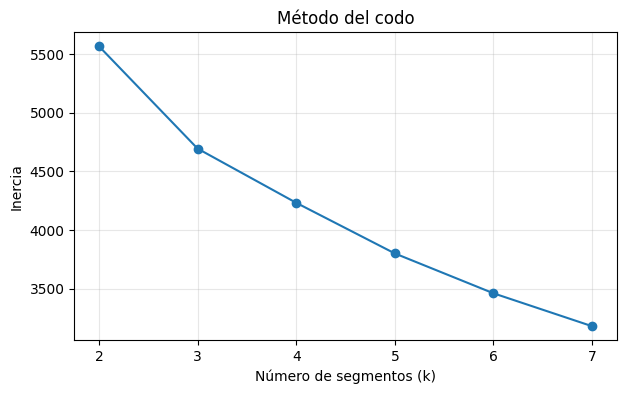

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    resultados_k["k"],
    resultados_k["inercia"],
    marker="o"
)

plt.xlabel(
    "Número de segmentos (k)"
)

plt.ylabel(
    "Inercia"
)

plt.title(
    "Método del codo"
)

plt.grid(alpha=0.3)

plt.show()

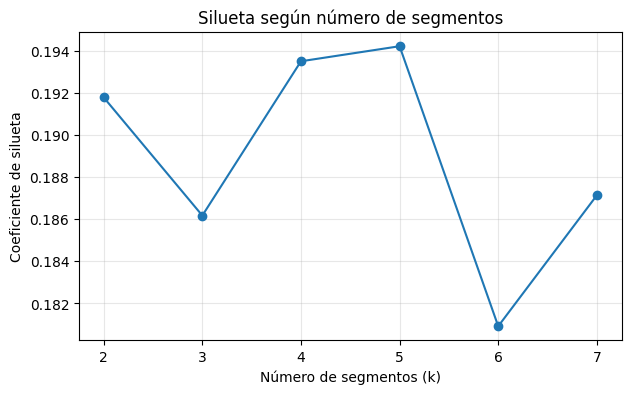

In [35]:
plt.figure(figsize=(7, 4))

plt.plot(
    resultados_k["k"],
    resultados_k["silueta"],
    marker="o"
)

plt.xlabel(
    "Número de segmentos (k)"
)

plt.ylabel(
    "Coeficiente de silueta"
)

plt.title(
    "Silueta según número de segmentos"
)

plt.grid(alpha=0.3)

plt.show()

In [36]:
mejor_fila = resultados_k.loc[
    resultados_k["silueta"].idxmax()
]

k_mejor_silueta = int(
    mejor_fila["k"]
)

print(
    "k con mayor silueta:",
    k_mejor_silueta
)

print(
    "Silueta:",
    round(
        mejor_fila["silueta"],
        4
    )
)

print(
    "Segmento más pequeño:",
    round(
        mejor_fila[
            "segmento_mas_pequeno_pct"
        ],
        2
    ),
    "%"
)

k con mayor silueta: 5
Silueta: 0.1942
Segmento más pequeño: 6.67 %


### 3.6 Selección del número de segmentos

Después de comparar valores de `k` entre 2 y 7, se seleccionó **k = 5**.

El valor de cinco segmentos obtuvo el mayor coeficiente de silueta, con **0.1942**, ligeramente superior a los demás valores evaluados. Además, el segmento más pequeño representa aproximadamente el **6.67% de los vendedores**, por lo que no se generan grupos excesivamente reducidos.

El método del codo también muestra una reducción progresiva de la inercia al aumentar el número de grupos. Considerando conjuntamente la silueta, la reducción de la inercia y la necesidad de obtener segmentos suficientemente diferenciados para definir acciones de negocio, se decidió trabajar con cinco grupos.

La magnitud relativamente baja de la silueta indica que algunos vendedores presentan características similares entre segmentos, por lo que los grupos deben interpretarse como perfiles operativos aproximados y no como categorías completamente separadas.

In [37]:
# Modelo K-Means final con k = 5

K_FINAL = 5

kmeans_final = KMeans(
    n_clusters=K_FINAL,
    random_state=42,
    n_init=20
)

segmentos = kmeans_final.fit_predict(
    X_escalado
)

# Agregar segmento a la tabla original
vendedores_segmentados = vendedores.copy()

vendedores_segmentados["segmento"] = segmentos

print(
    "Número de segmentos:",
    vendedores_segmentados["segmento"]
    .nunique()
)

print("\nVendedores por segmento:")

display(
    vendedores_segmentados["segmento"]
    .value_counts()
    .sort_index()
    .to_frame("vendedores")
)

Número de segmentos: 5

Vendedores por segmento:


,vendedores
segmento,
0,334
1,241
2,140
3,67
4,223


### 3.7 Perfil de los segmentos

Una vez asignado cada vendedor a uno de los cinco grupos, se analizan los valores promedio de las variables originales. Se utilizan los valores sin transformación logarítmica ni estandarización para que los perfiles sean interpretables desde el punto de vista del negocio.

In [38]:
# Perfil promedio de cada segmento

variables_perfil = [
    "pedidos_entregados",
    "ventas_total",
    "ticket_promedio",
    "items_por_pedido",
    "flete_relativo",
    "tasa_retraso",
    "categorias_distintas"
]

perfil_segmentos = (
    vendedores_segmentados
    .groupby("segmento")[variables_perfil]
    .mean()
    .round(3)
)

# Cantidad de vendedores por segmento
perfil_segmentos.insert(
    0,
    "n_vendedores",
    vendedores_segmentados
    .groupby("segmento")
    .size()
)

display(perfil_segmentos)

,n_vendedores,pedidos_entregados,ventas_total,ticket_promedio,items_por_pedido,flete_relativo,tasa_retraso,categorias_distintas
segmento,,,,,,,,
0,334,31.452,7163.011,246.836,1.073,0.134,0.054,2.371
1,241,35.813,1782.893,55.407,1.124,0.391,0.067,2.369
2,140,31.743,4856.374,178.674,1.087,0.191,0.213,1.929
3,67,28.075,4312.429,163.177,1.627,0.290,0.082,2.090
4,223,217.744,26136.523,124.026,1.110,0.220,0.079,5.785


In [39]:
# Participación porcentual de cada segmento

distribucion_segmentos = (
    vendedores_segmentados["segmento"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .rename("porcentaje")
)

display(
    distribucion_segmentos.to_frame()
)

,porcentaje
segmento,
0,33.23
1,23.98
2,13.93
3,6.67
4,22.19


### 3.8 Visualización de los segmentos mediante PCA

Para representar gráficamente los grupos se aplica Análisis de Componentes Principales (PCA). Esta técnica reduce las variables utilizadas en K-Means a dos componentes, permitiendo visualizar la posición relativa de los vendedores y la separación aproximada entre los segmentos.

El PCA se utiliza únicamente para visualización; los grupos fueron calculados utilizando todas las variables seleccionadas.

Varianza explicada por PC1: 34.04 %
Varianza explicada por PC2: 24.16 %
Varianza total representada: 58.2 %


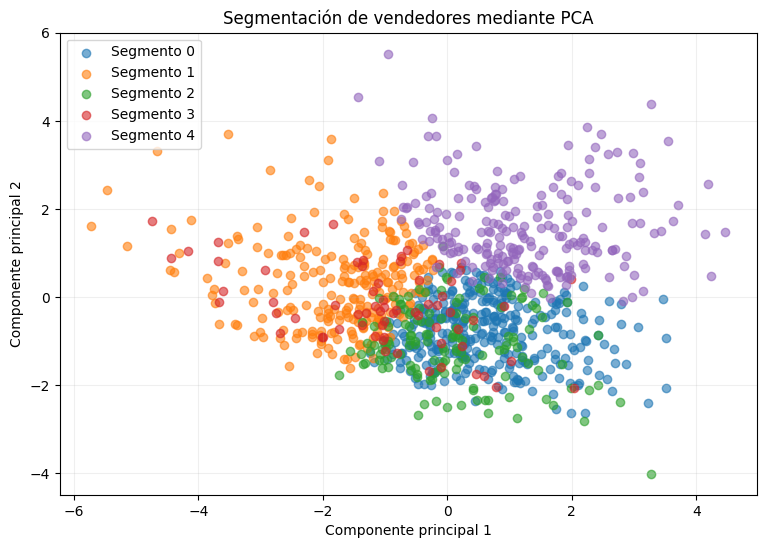

In [40]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(
    n_components=2,
    random_state=42
)

componentes = pca.fit_transform(
    X_escalado
)

pca_df = pd.DataFrame({
    "PC1": componentes[:, 0],
    "PC2": componentes[:, 1],
    "segmento": vendedores_segmentados["segmento"].values
})

print(
    "Varianza explicada por PC1:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)

print(
    "Varianza explicada por PC2:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)

print(
    "Varianza total representada:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

plt.figure(figsize=(9, 6))

for segmento in sorted(
    pca_df["segmento"].unique()
):
    datos_segmento = pca_df[
        pca_df["segmento"] == segmento
    ]

    plt.scatter(
        datos_segmento["PC1"],
        datos_segmento["PC2"],
        label=f"Segmento {segmento}",
        alpha=0.6
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Segmentación de vendedores mediante PCA")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

### 3.9 Interpretación de la visualización PCA

Los dos primeros componentes principales explican conjuntamente el **58.20% de la variabilidad** presente en las variables utilizadas para segmentar a los vendedores. El primer componente representa el 34.04% y el segundo el 24.16%.

La visualización muestra zonas donde algunos segmentos se diferencian con mayor claridad, pero también existe solapamiento entre varios grupos. Este resultado es consistente con el coeficiente de silueta obtenido anteriormente, que indica que los perfiles de los vendedores no forman grupos completamente separados.

Por esta razón, los segmentos deben interpretarse como **perfiles operativos y comerciales predominantes**, y no como categorías rígidas. El PCA se utiliza únicamente para facilitar la visualización; la asignación de los segmentos fue realizada por K-Means utilizando todas las variables seleccionadas.

### 3.10 Perfil y nombre de los segmentos

A partir de los valores promedio obtenidos para cada grupo, se asignaron nombres descriptivos que resumen sus principales características.

**Segmento 0 — Vendedores de alto valor y operación estable**

Este grupo contiene 334 vendedores. Presenta un ticket promedio elevado de aproximadamente **246.84**, ventas promedio totales de **7,163.01**, un flete relativo bajo de **0.134** y una tasa de retraso de solamente **5.4%**.

El perfil corresponde a vendedores que manejan pedidos de mayor valor y mantienen un desempeño logístico relativamente estable.

**Segmento 1 — Vendedores de bajo ticket y alto costo relativo de flete**

Está compuesto por 241 vendedores. Tiene el ticket promedio más bajo, aproximadamente **55.41**, y ventas promedio de **1,782.89**. Su característica más destacada es un flete relativo de **0.391**, el más alto entre los cinco segmentos.

Esto significa que el costo del transporte representa una proporción considerable del valor de los productos vendidos.

**Segmento 2 — Vendedores con mayor riesgo de retraso**

Este grupo contiene 140 vendedores y presenta una tasa promedio de retraso de **21.3%**, claramente superior a la observada en los demás segmentos.

Sus ventas promedio son de aproximadamente **4,856.37** y su ticket promedio alcanza **178.67**. Su característica diferenciadora principal es, por tanto, el comportamiento logístico asociado con las entregas tardías.

**Segmento 3 — Vendedores de pedidos más complejos**

Este es el segmento más pequeño, con 67 vendedores. Presenta aproximadamente **1.63 artículos por pedido**, el valor más alto entre todos los grupos. También registra un flete relativo relativamente elevado de **0.290**.

Su perfil sugiere operaciones con pedidos que contienen una mayor cantidad de artículos y que pueden requerir una gestión logística más compleja.

**Segmento 4 — Vendedores de alto volumen y amplia diversidad**

Está formado por 223 vendedores y se diferencia claramente por su escala de operación. Maneja en promedio aproximadamente **217.74 pedidos entregados**, ventas totales de **26,136.52** y alrededor de **5.79 categorías diferentes**.

Es el grupo con mayor volumen de pedidos, mayores ventas y mayor diversidad de categorías, por lo que representa a los vendedores de mayor escala dentro de la plataforma.

### 3.11 Acciones recomendadas por segmento

La segmentación permite proponer estrategias diferenciadas según las características de cada grupo.

| Segmento | Perfil | Acción recomendada |
|---|---|---|
| **0** | Alto valor y operación estable | Mantener condiciones comerciales favorables y realizar seguimiento preventivo para conservar su buen desempeño logístico. |
| **1** | Bajo ticket y alto flete relativo | Revisar alternativas de transporte, consolidación de envíos o políticas de flete que permitan reducir el peso del costo logístico sobre el valor del pedido. |
| **2** | Mayor riesgo de retraso | Priorizar el seguimiento logístico, revisar tiempos de preparación y transporte e identificar las principales causas de las entregas tardías. |
| **3** | Pedidos más complejos | Revisar procesos de preparación, empaquetado y consolidación de artículos para reducir la complejidad y el costo de los pedidos con múltiples productos. |
| **4** | Alto volumen y amplia diversidad | Proporcionar atención prioritaria y herramientas de gestión para vendedores de gran escala, ya que concentran un volumen considerable de pedidos y ventas. |

Estas acciones no implican que pertenecer a un segmento sea por sí mismo la causa de un determinado resultado. Los grupos sirven para identificar patrones y orientar decisiones que posteriormente deben complementarse con análisis operativo.

In [41]:
# Nombres comerciales de los segmentos

nombres_segmentos = {
    0: "Alto valor y operación estable",
    1: "Bajo ticket y alto flete",
    2: "Mayor riesgo de retraso",
    3: "Pedidos más complejos",
    4: "Alto volumen y diversidad"
}

vendedores_segmentados["nombre_segmento"] = (
    vendedores_segmentados["segmento"]
    .map(nombres_segmentos)
)

display(
    vendedores_segmentados[
        [
            "seller_id",
            "segmento",
            "nombre_segmento",
            "pedidos_entregados",
            "ventas_total",
            "tasa_retraso"
        ]
    ].head(10)
)

,seller_id,segmento,nombre_segmento,pedidos_entregados,ventas_total,tasa_retraso
0,4a3ca9315b744ce9f8e9374361493884,4,Alto volumen y diversidad,1572,177432.72,0.119593
1,cc419e0650a3c5ba77189a1882b7556a,4,Alto volumen y diversidad,1556,94761.13,0.063625
2,1f50f920176fa81dab994f9023523100,4,Alto volumen y diversidad,1290,99039.79,0.113178
3,6560211a19b47992c3666cc44a7e94c0,4,Alto volumen y diversidad,1281,82927.83,0.070258
4,da8622b14eb17ae2831f4ac5b9dab84a,4,Alto volumen y diversidad,1117,139613.93,0.078782
5,7a67c85e85bb2ce8582c35f2203ad736,4,Alto volumen y diversidad,1085,133336.31,0.058065
6,955fee9216a65b617aa5c0531780ce60,4,Alto volumen y diversidad,1039,104923.57,0.083734
7,3d871de0142ce09b7081e2b9d1733cb1,4,Alto volumen y diversidad,980,85529.70,0.063265
8,ea8482cd71df3c1969d7b9473ff13abc,4,Alto volumen y diversidad,960,30755.13,0.109375
9,7c67e1448b00f6e969d365cea6b010ab,4,Alto volumen y diversidad,896,172317.99,0.101562


In [42]:
acciones_segmentos = {
    0: "Mantener condiciones favorables y seguimiento preventivo.",
    1: "Revisar alternativas para reducir el peso del costo de flete.",
    2: "Priorizar seguimiento logístico y causas de retraso.",
    3: "Optimizar preparación y consolidación de pedidos.",
    4: "Ofrecer atención prioritaria y herramientas para operaciones de gran escala."
}

vendedores_segmentados["accion_recomendada"] = (
    vendedores_segmentados["segmento"]
    .map(acciones_segmentos)
)

display(
    vendedores_segmentados[
        [
            "seller_id",
            "nombre_segmento",
            "accion_recomendada"
        ]
    ].head()
)

,seller_id,nombre_segmento,accion_recomendada
0,4a3ca9315b744ce9f8e9374361493884,Alto volumen y diversidad,Ofrecer atención prioritaria y herramientas pa...
1,cc419e0650a3c5ba77189a1882b7556a,Alto volumen y diversidad,Ofrecer atención prioritaria y herramientas pa...
2,1f50f920176fa81dab994f9023523100,Alto volumen y diversidad,Ofrecer atención prioritaria y herramientas pa...
3,6560211a19b47992c3666cc44a7e94c0,Alto volumen y diversidad,Ofrecer atención prioritaria y herramientas pa...
4,da8622b14eb17ae2831f4ac5b9dab84a,Alto volumen y diversidad,Ofrecer atención prioritaria y herramientas pa...


### 3.12 Resumen final de los segmentos

In [43]:
resumen_final_segmentos = perfil_segmentos.copy()

resumen_final_segmentos["nombre"] = [
    nombres_segmentos[i]
    for i in resumen_final_segmentos.index
]

resumen_final_segmentos["porcentaje_vendedores"] = (
    vendedores_segmentados["segmento"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

columnas_orden = [
    "nombre",
    "n_vendedores",
    "porcentaje_vendedores",
    "pedidos_entregados",
    "ventas_total",
    "ticket_promedio",
    "items_por_pedido",
    "flete_relativo",
    "tasa_retraso",
    "categorias_distintas"
]

resumen_final_segmentos = (
    resumen_final_segmentos[columnas_orden]
)

display(resumen_final_segmentos)

,nombre,n_vendedores,porcentaje_vendedores,pedidos_entregados,ventas_total,ticket_promedio,items_por_pedido,flete_relativo,tasa_retraso,categorias_distintas
segmento,,,,,,,,,,
0,Alto valor y operación estable,334,33.23,31.452,7163.011,246.836,1.073,0.134,0.054,2.371
1,Bajo ticket y alto flete,241,23.98,35.813,1782.893,55.407,1.124,0.391,0.067,2.369
2,Mayor riesgo de retraso,140,13.93,31.743,4856.374,178.674,1.087,0.191,0.213,1.929
3,Pedidos más complejos,67,6.67,28.075,4312.429,163.177,1.627,0.290,0.082,2.090
4,Alto volumen y diversidad,223,22.19,217.744,26136.523,124.026,1.110,0.220,0.079,5.785


### 3.13 Exportación de resultados

Los resultados de la segmentación se guardan para utilizarlos posteriormente en la aplicación de Streamlit sin necesidad de volver a ejecutar el algoritmo de agrupamiento.

In [44]:
# Guardar vendedores segmentados

vendedores_segmentados.to_csv(
    "segmentacion_vendedores.csv",
    index=False
)

# Guardar perfil de los segmentos
resumen_final_segmentos.to_csv(
    "perfil_segmentos.csv",
    index=True
)

print(
    "segmentacion_vendedores.csv guardado correctamente."
)

print(
    "perfil_segmentos.csv guardado correctamente."
)

segmentacion_vendedores.csv guardado correctamente.
perfil_segmentos.csv guardado correctamente.


In [45]:
import os

print(
    "Existe segmentacion_vendedores.csv:",
    os.path.exists(
        "segmentacion_vendedores.csv"
    )
)

print(
    "Existe perfil_segmentos.csv:",
    os.path.exists(
        "perfil_segmentos.csv"
    )
)

Existe segmentacion_vendedores.csv: True
Existe perfil_segmentos.csv: True


### 3.14 Conclusión

La segmentación mediante K-Means permitió identificar **cinco perfiles de vendedores** con diferencias principalmente relacionadas con su volumen de operación, valor de las ventas, costo relativo del flete, complejidad de los pedidos y comportamiento de entrega.

El segmento 4 concentra vendedores de mayor escala y diversidad de categorías, mientras que el segmento 0 presenta pedidos de alto valor y un comportamiento logístico estable. El segmento 1 destaca por el elevado peso relativo del flete, el segmento 2 por una mayor tasa de retraso y el segmento 3 por una mayor cantidad de artículos por pedido.

Aunque el coeficiente de silueta de **0.1942** y la visualización PCA muestran que existe solapamiento entre algunos vendedores, los perfiles obtenidos permiten distinguir patrones suficientemente útiles para orientar estrategias diferenciadas.

La segmentación no debe utilizarse como una clasificación rígida ni como mecanismo automático para penalizar vendedores. Su principal utilidad es apoyar la identificación de necesidades distintas de seguimiento, logística y acompañamiento comercial.

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [46]:
!pip install -q transformers

### 4.1 Objetivo del análisis de sentimiento

En esta sección se analiza el contenido textual de las reseñas de los clientes mediante un modelo preentrenado de Deep Learning.

Se utiliza el modelo `cardiffnlp/twitter-xlm-roberta-base-sentiment`, que permite clasificar textos en sentimiento positivo, neutral o negativo y tiene soporte para portugués.

El propósito es comparar el sentimiento expresado en el comentario con la calificación en estrellas y detectar casos en los que ambos no coinciden.

Los comentarios se utilizan exclusivamente en esta sección de análisis y **no forman parte del modelo de riesgo de la Parte 2**, ya que la reseña todavía no existe en el momento en que se realiza aquella predicción.

### 4.2 Obtención de los comentarios

Se seleccionan reseñas que contienen texto no vacío. Cuando un pedido presenta más de una reseña, se conserva la más reciente según `review_answer_timestamp`, manteniendo el mismo criterio utilizado anteriormente en el proyecto.

A partir de estas reseñas se extrae una muestra aleatoria reproducible utilizando una semilla fija.

In [47]:
# TU CÓDIGO AQUÍ
# Obtener comentarios no vacíos de la base de datos

consulta_comentarios = """
WITH resena_reciente AS (
    SELECT DISTINCT ON (order_id)
        order_id,
        review_score,
        review_comment_message,
        review_answer_timestamp

    FROM final.order_reviews

    WHERE
        review_comment_message IS NOT NULL
        AND BTRIM(review_comment_message) <> ''

    ORDER BY
        order_id,
        review_answer_timestamp DESC NULLS LAST
)

SELECT
    order_id,
    review_score,
    review_comment_message,
    review_answer_timestamp

FROM resena_reciente;
"""

comentarios = pd.read_sql(
    consulta_comentarios,
    motor
)

print(
    "Comentarios disponibles:",
    len(comentarios)
)

display(
    comentarios.head()
)

Comentarios disponibles: 33458


,order_id,review_score,review_comment_message,review_answer_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,5,"Perfeito, produto entregue antes do combinado.",2017-09-22 10:57:03
1,000229ec398224ef6ca0657da4fc703e,5,Chegou antes do prazo previsto e o produto sur...,2018-01-23 16:06:31
2,00042b26cf59d7ce69dfabb4e55b4fd9,5,Gostei pois veio no prazo determinado .,2017-03-03 10:54:59
3,0005a1a1728c9d785b8e2b08b904576c,1,Na descrição do produto quando fui efetuar a c...,2018-04-02 00:52:01
4,00061f2a7bc09da83e415a52dc8a4af1,5,A caixa do produto veio com uma pequena avaria...,2018-03-30 04:04:56


### 4.3 Selección de la muestra

Para garantizar reproducibilidad se utiliza `random_state=42`.

Se analizan **1,500 comentarios**, superando el mínimo de 1,000 requerido por el proyecto.

In [48]:
# Verificar que existen suficientes comentarios

assert len(comentarios) >= 1000, (
    "No existen suficientes comentarios para cumplir el mínimo requerido."
)

TAMANO_MUESTRA = min(
    1500,
    len(comentarios)
)

sentimiento_muestra = (
    comentarios
    .sample(
        n=TAMANO_MUESTRA,
        random_state=42
    )
    .reset_index(drop=True)
)

print(
    "Comentarios seleccionados:",
    len(sentimiento_muestra)
)

display(
    sentimiento_muestra.head()
)

Comentarios seleccionados: 1500


,order_id,review_score,review_comment_message,review_answer_timestamp
0,6f2d341a759b59c051aa9fcbaf2dcba1,3,produto correto e no prazo o cd veio solto de...,2017-11-08 15:48:26
1,a8096d0b94faa1314dbd562efc6a0967,4,"a entrega dos produtos e muito rapido ,mais de...",2018-02-24 15:48:31
2,e4c35e0087c99d3416b1d90566f28e3f,4,"Produto entregue antes do prazo, satisfeita co...",2018-05-24 11:38:51
3,c09477fe82b2b17f5f35d61a5237ba39,5,"Produto com ótimo acabamento, encaixe correto ...",2018-04-19 13:28:15
4,63ad650ce1c19577c3eaa386f8752701,2,Recebi apenas a bolsa a cortina não recebi.,2017-05-25 17:40:10


### 4.4 Conversión de estrellas a categorías de sentimiento

Para poder comparar las estrellas con la salida del modelo, las calificaciones se agrupan en las mismas tres categorías:

- 1 y 2 estrellas → **negativo**
- 3 estrellas → **neutral**
- 4 y 5 estrellas → **positivo**

In [49]:
def sentimiento_estrellas(score):
    if score in [1, 2]:
        return "negativo"
    elif score == 3:
        return "neutral"
    else:
        return "positivo"


sentimiento_muestra["sentimiento_estrellas"] = (
    sentimiento_muestra["review_score"]
    .apply(sentimiento_estrellas)
)

display(
    sentimiento_muestra[
        [
            "review_score",
            "sentimiento_estrellas"
        ]
    ]
    .value_counts()
    .to_frame("cantidad")
)

,,cantidad
review_score,sentimiento_estrellas,
5,positivo,723
1,negativo,323
4,positivo,243
3,neutral,120
2,negativo,91


In [50]:
!pip install -q transformers sentencepiece

In [51]:
import torch

print(
    "GPU disponible:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

GPU disponible: True
GPU: Tesla T4


In [52]:
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

MODELO_SENTIMIENTO = (
    "cardiffnlp/"
    "twitter-xlm-roberta-base-sentiment"
)

clasificador = pipeline(
    "sentiment-analysis",
    model=MODELO_SENTIMIENTO,
    device=device
)

print(
    "Modelo cargado correctamente."
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Modelo cargado correctamente.


In [53]:
clasificador(
    [
        "Produto chegou antes do prazo, recomendo!"
    ]
)

[{'label': 'positive', 'score': 0.8764356970787048}]

### 4.6 Clasificación de sentimiento con Deep Learning

El modelo preentrenado se aplica a los comentarios en lotes de 32 textos. Se utiliza truncamiento para evitar errores en comentarios que excedan el tamaño máximo aceptado por el modelo.

Además de la categoría de sentimiento, se conserva la puntuación de confianza entregada por el modelo.

In [54]:
# Convertir comentarios a lista de texto

textos = (
    sentimiento_muestra[
        "review_comment_message"
    ]
    .astype(str)
    .tolist()
)

resultados_sentimiento = clasificador(
    textos,
    batch_size=32,
    truncation=True,
    max_length=512
)

print(
    "Clasificaciones realizadas:",
    len(resultados_sentimiento)
)

Clasificaciones realizadas: 1500


In [55]:
# Normalizar las etiquetas del modelo

mapa_etiquetas = {
    "negative": "negativo",
    "neutral": "neutral",
    "positive": "positivo",

    # Seguridad por si el modelo devuelve LABEL_X
    "label_0": "negativo",
    "label_1": "neutral",
    "label_2": "positivo"
}

sentimiento_muestra["sentimiento_modelo"] = [
    mapa_etiquetas.get(
        resultado["label"].lower(),
        resultado["label"].lower()
    )
    for resultado in resultados_sentimiento
]

sentimiento_muestra["confianza_modelo"] = [
    resultado["score"]
    for resultado in resultados_sentimiento
]

display(
    sentimiento_muestra[
        [
            "review_comment_message",
            "review_score",
            "sentimiento_estrellas",
            "sentimiento_modelo",
            "confianza_modelo"
        ]
    ].head(10)
)

,review_comment_message,review_score,sentimiento_estrellas,sentimiento_modelo,confianza_modelo
0,produto correto e no prazo o cd veio solto de...,3,neutral,neutral,0.753888
1,"a entrega dos produtos e muito rapido ,mais de...",4,positivo,negativo,0.513032
2,"Produto entregue antes do prazo, satisfeita co...",4,positivo,positivo,0.850506
3,"Produto com ótimo acabamento, encaixe correto ...",5,positivo,positivo,0.927005
4,Recebi apenas a bolsa a cortina não recebi.,2,negativo,neutral,0.726330
5,Obrigada chegou corretamente.,5,positivo,positivo,0.800542
6,Nunca tive problemas com as entregas desse sit...,5,positivo,positivo,0.707642
7,recebi meu pedido faltando um kit progressiva....,1,negativo,negativo,0.664917
8,Há como me atualizar quando será entregue este...,1,negativo,neutral,0.901806
9,Tudo Certo.\r\nMuito Grato. :)\r\n,4,positivo,positivo,0.930764


### 4.7 Verificar categorías obtenidas

In [56]:
print(
    "Sentimientos producidos por el modelo:"
)

print(
    sentimiento_muestra[
        "sentimiento_modelo"
    ].value_counts()
)

print(
    "\nSentimientos derivados de estrellas:"
)

print(
    sentimiento_muestra[
        "sentimiento_estrellas"
    ].value_counts()
)

Sentimientos producidos por el modelo:
sentimiento_modelo
positivo    786
negativo    387
neutral     327
Name: count, dtype: int64

Sentimientos derivados de estrellas:
sentimiento_estrellas
positivo    966
negativo    414
neutral     120
Name: count, dtype: int64


### 4.8 Comparación entre estrellas y sentimiento del texto

Se compara la categoría derivada de las estrellas con la clasificación obtenida por el modelo de lenguaje.

La tabla cruzada permite observar cuántos comentarios coinciden o no coinciden con la valoración numérica proporcionada por el cliente.

In [57]:
tabla_cruzada = pd.crosstab(
    sentimiento_muestra[
        "sentimiento_estrellas"
    ],
    sentimiento_muestra[
        "sentimiento_modelo"
    ],
    margins=True
)

display(tabla_cruzada)

sentimiento_modelo,negativo,neutral,positivo,All
sentimiento_estrellas,,,,
negativo,270,130,14,414
neutral,54,43,23,120
positivo,63,154,749,966
All,387,327,786,1500


In [58]:
#Porcentaje por fila
tabla_cruzada_pct = (
    pd.crosstab(
        sentimiento_muestra[
            "sentimiento_estrellas"
        ],
        sentimiento_muestra[
            "sentimiento_modelo"
        ],
        normalize="index"
    )
    * 100
).round(2)

display(
    tabla_cruzada_pct
)

sentimiento_modelo,negativo,neutral,positivo
sentimiento_estrellas,,,
negativo,65.22,31.40,3.38
neutral,45.00,35.83,19.17
positivo,6.52,15.94,77.54


### 4.9 Porcentaje de coincidencia

In [59]:
sentimiento_muestra["coincide"] = (
    sentimiento_muestra[
        "sentimiento_estrellas"
    ]
    ==
    sentimiento_muestra[
        "sentimiento_modelo"
    ]
)

porcentaje_coincidencia = (
    sentimiento_muestra[
        "coincide"
    ].mean()
    * 100
)

cantidad_coinciden = (
    sentimiento_muestra[
        "coincide"
    ].sum()
)

cantidad_desacuerdos = (
    (~sentimiento_muestra[
        "coincide"
    ]).sum()
)

print(
    "Coincidencia:",
    round(
        porcentaje_coincidencia,
        2
    ),
    "%"
)

print(
    "Comentarios que coinciden:",
    cantidad_coinciden
)

print(
    "Comentarios con desacuerdo:",
    cantidad_desacuerdos
)

Coincidencia: 70.8 %
Comentarios que coinciden: 1062
Comentarios con desacuerdo: 438


#### Interpretación de la coincidencia entre estrellas y texto

De los **1,500 comentarios analizados**, el sentimiento detectado por el modelo coincidió con la categoría derivada de las estrellas en **1,062 casos**, equivalente al **70.8%** de la muestra. En los **438 comentarios restantes (29.2%)** existió algún tipo de desacuerdo.

La tabla cruzada muestra que la mayor coincidencia se obtuvo en las reseñas positivas. De los **966 comentarios clasificados como positivos según las estrellas**, el modelo identificó correctamente esa misma categoría en **749 casos (77.54%)**.

En las reseñas negativas, la coincidencia también fue considerable: de **414 comentarios negativos según las estrellas**, el modelo clasificó **270 como negativos (65.22%)**.

El grupo más difícil fue el de las reseñas de **3 estrellas**, consideradas neutrales en este análisis. De los 120 casos, solamente **43 (35.83%)** fueron clasificados como neutrales por el modelo; 54 fueron considerados negativos y 23 positivos. Esto sugiere que una calificación de 3 estrellas puede contener opiniones mixtas que no necesariamente se expresan con lenguaje neutral.

También se observa que el modelo asignó la categoría neutral con mayor frecuencia que la clasificación basada en estrellas. En particular, **154 comentarios positivos** y **130 negativos** según las estrellas fueron considerados neutrales por el modelo. Esto puede ocurrir cuando el comentario utiliza un lenguaje breve, objetivo o poco emocional.

Por lo tanto, el resultado de 70.8% indica una relación importante entre las estrellas y el sentimiento del texto, pero también demuestra que ambas fuentes aportan información diferente y que no siempre una puntuación numérica representa exactamente la forma en que el cliente expresa su experiencia.

### 4.10 Análisis de desacuerdos

Se revisan manualmente comentarios en los que la categoría derivada de las estrellas no coincide con el sentimiento detectado por el modelo.

El objetivo es determinar si el desacuerdo puede explicarse por limitaciones del modelo, como textos cortos, ironía o ambigüedad, o por inconsistencias entre el comentario escrito y la puntuación asignada por el cliente.

In [60]:
desacuerdos = (
    sentimiento_muestra[
        ~sentimiento_muestra["coincide"]
    ]
    .copy()
)

print(
    "Total de desacuerdos:",
    len(desacuerdos)
)

desacuerdos_muestra = (
    desacuerdos
    .sample(
        n=min(10, len(desacuerdos)),
        random_state=42
    )
    [
        [
            "order_id",
            "review_score",
            "review_comment_message",
            "sentimiento_estrellas",
            "sentimiento_modelo",
            "confianza_modelo"
        ]
    ]
)

display(
    desacuerdos_muestra
)

Total de desacuerdos: 438


,order_id,review_score,review_comment_message,sentimiento_estrellas,sentimiento_modelo,confianza_modelo
1253,81feb133966d4c93d65ba18e9b5fca54,3,"O produto veio errado,",neutral,negativo,0.736198
282,d248ddd0378083cb6c2bc7b9881d37d4,1,comunico aos responsáveis que só recebe um kit...,negativo,neutral,0.708776
939,6d3f615ed5f5521c748aa7a71308a880,5,Produto entregue conforme a compra e dentro do...,positivo,neutral,0.781410
1354,ee27c5db38b1e5eba4ca12bbe0cef731,4,"Comprei dois produtos, o primeiro chegou certi...",positivo,neutral,0.705135
1494,f6974499820661b92dd1922750d6f0d0,5,Tecido de qualidade e envio antes do prazo,positivo,neutral,0.609013
981,92c3a5b09e48e84587b55b833b901d81,5,Compra sem problemas,positivo,neutral,0.601288
731,ce5f998d724ed1ac61c890e33b24a33f,1,Cadê meu produto ... pra querer saber minha op...,negativo,neutral,0.527291
299,4832ff0402c0e07fcf802721babe2b05,5,//////////////////////////////////////////////...,positivo,negativo,0.443813
1484,77b8e495f75bbdf52e3a29bc46188eef,5,Não habia o produto. Me reembolsaram sem probl...,positivo,neutral,0.572977
1389,3b506802b619f7a3d43a4180ae13698f,5,Produto é como imaginava e foi entregue antes ...,positivo,neutral,0.609666


#### Análisis manual de desacuerdos

Se revisaron manualmente algunos casos en los que el sentimiento derivado de las estrellas no coincidió con la clasificación realizada por el modelo.

| Caso | Estrellas | Texto observado | Estrellas agrupadas | Modelo | Análisis |
|---|---:|---|---|---|---|
| 1 | 3 | `O produto veio errado,` | Neutral | Negativo | **Inconsistencia entre estrellas y texto.** Aunque las 3 estrellas se agrupan como neutrales, el comentario expresa claramente una experiencia negativa al indicar que el producto llegó equivocado. En este caso, la clasificación negativa del modelo resulta coherente con el contenido escrito. |
| 2 | 5 | `Produto entregue conforme a compra e dentro do...` | Positivo | Neutral | **Limitación del modelo / lenguaje objetivo.** El cliente otorgó 5 estrellas y describe que el producto fue entregado de acuerdo con la compra, pero el comentario utiliza una redacción principalmente informativa. El modelo puede interpretar esta falta de expresiones emocionales como neutralidad. |
| 3 | 5 | `Tecido de qualidade e envio antes do prazo` | Positivo | Neutral | **Probable error del modelo.** El comentario contiene elementos claramente favorables: buena calidad y entrega antes del plazo. La clasificación neutral parece subestimar el sentimiento positivo expresado por el cliente. |
| 4 | 5 | `Compra sem problemas` | Positivo | Neutral | **Texto corto con positividad implícita.** La frase indica una experiencia satisfactoria, pero no utiliza palabras fuertemente emocionales. Debido a su brevedad, el modelo la interpretó como neutral aunque las 5 estrellas indican una valoración positiva. |
| 5 | 1 | `Cadê meu produto ... pra querer saber minha op...` | Negativo | Neutral | **Probable error del modelo por lenguaje coloquial y fragmentado.** La calificación de una estrella y la pregunta sobre dónde está el producto muestran insatisfacción. Sin embargo, la forma informal y fragmentada del comentario puede dificultar la detección automática del sentimiento negativo. |

Los desacuerdos muestran que no todos los casos representan necesariamente un error del modelo. En algunas situaciones existe una diferencia real entre la puntuación asignada por el cliente y lo escrito en el comentario. En otras, el modelo tiene dificultades con textos muy breves, expresiones implícitas, lenguaje informal o comentarios que describen hechos sin utilizar palabras claramente positivas o negativas.

También existen comentarios ambiguos o mixtos. Por ejemplo, un cliente puede mencionar un problema con el producto pero también indicar que recibió un reembolso correctamente. En esos casos, una única etiqueta de sentimiento puede no representar completamente la experiencia descrita.

### 4.11 Guardar resultados para Streamlit

In [61]:
# Guardar resultados completos del análisis

sentimiento_muestra.to_csv(
    "sentimiento_muestra.csv",
    index=False
)

print(
    "sentimiento_muestra.csv guardado correctamente."
)

sentimiento_muestra.csv guardado correctamente.


In [62]:
import os

print(
    "Existe sentimiento_muestra.csv:",
    os.path.exists(
        "sentimiento_muestra.csv"
    )
)

print(
    "Filas guardadas:",
    len(sentimiento_muestra)
)

Existe sentimiento_muestra.csv: True
Filas guardadas: 1500


### 4.12 Conclusión del análisis de sentimiento

El análisis de sentimiento permitió complementar la información proporcionada por las estrellas con el contenido escrito de las reseñas. En la muestra de **1,500 comentarios**, el sentimiento detectado por el modelo coincidió con la categoría derivada de las estrellas en **70.8% de los casos**, mientras que en **29.2%** existieron desacuerdos.

Estos resultados muestran que las estrellas y el texto están relacionados, pero no representan exactamente lo mismo. La puntuación resume la experiencia del cliente en un valor numérico, mientras que el comentario puede revelar detalles específicos sobre problemas de entrega, calidad del producto, cumplimiento de expectativas, reembolsos o experiencias mixtas.

Los desacuerdos revisados mostraron que algunos clientes asignan una puntuación que no refleja completamente lo que escriben. También se identificaron limitaciones del modelo ante comentarios muy cortos, lenguaje informal, expresiones implícitas y textos con elementos positivos y negativos al mismo tiempo.

Para Olist, este análisis puede utilizarse como complemento de las estrellas para identificar con mayor detalle las causas de satisfacción o insatisfacción de los clientes. Por ejemplo, permitiría detectar comentarios negativos dentro de reseñas con puntuaciones relativamente altas, priorizar casos que requieren revisión y analizar patrones frecuentes relacionados con entregas, productos o atención al cliente.

Por lo tanto, el análisis automático del texto aporta información cualitativa que las estrellas por sí solas no pueden mostrar. Sin embargo, sus resultados deben utilizarse como apoyo para el análisis y no como una clasificación absoluta, ya que el lenguaje natural puede contener ambigüedad, ironía, expresiones breves o experiencias mixtas que requieren interpretación adicional.

### Preguntas

**1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?**

El sentimiento del texto coincide con las estrellas en **70.8% de los casos**. De los 1,500 comentarios analizados, 1,062 coincidieron y 438 no coincidieron.

La mayor confusión estuvo en las reseñas de **3 estrellas**, ya que muchos comentarios de este grupo fueron clasificados por el modelo como positivos o negativos en lugar de neutrales. Esto puede pasar porque una reseña de 3 estrellas puede contener opiniones mezcladas.

---

**2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?**

Se encontraron distintos tipos de desacuerdos. Algunos ejemplos fueron:

| Caso | Estrellas | Comentario | Modelo | Clasificación |
|---|---:|---|---|---|
| 1 | 3 | `O produto veio errado,` | Negativo | **Cliente**: puso 3 estrellas, pero el comentario expresa algo negativo. |
| 2 | 5 | `Produto entregue conforme a compra...` | Neutral | **Modelo**: el comentario es positivo, pero fue interpretado como neutral. |
| 3 | 5 | `Tecido de qualidade e envio antes do prazo` | Neutral | **Modelo**: habla de buena calidad y entrega rápida, por lo que parece positivo. |
| 4 | 5 | `Compra sem problemas` | Neutral | **Modelo**: el texto es corto, pero refleja una experiencia positiva. |
| 5 | 1 | `Cadê meu produto...` | Neutral | **Modelo**: el cliente muestra molestia, pero el modelo no lo detectó como negativo. |

Esto muestra que a veces el problema está en el modelo, pero también puede pasar que las estrellas no coincidan completamente con lo que escribió el cliente.

---

**3. ¿Qué dice el texto que las estrellas no dicen?**

Las estrellas indican si la experiencia fue buena o mala, pero el texto explica **qué fue lo que pasó**.

Por ejemplo, el comentario puede indicar si hubo problemas con la entrega, si el producto llegó equivocado, si tuvo buena calidad o si el cliente recibió un reembolso.

Por eso, el texto ayuda a Olist a entender mejor las razones de satisfacción o insatisfacción de los clientes y complementa la información de las estrellas.

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

In [63]:
# TU CÓDIGO AQUÍ

## Parte 5 · Despliegue

- URL de la API en Render: **[pegar aquí]**
- URL de la app de Streamlit: **[pegar aquí]**

Versiones de este entorno (para su `requirements.txt` de la API):

In [64]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1


### 5.1 Preparación de la API

Se implementa una API con FastAPI para exponer el modelo de riesgo desarrollado en la Parte 2.

La API recibe las 17 variables del contrato, calcula la probabilidad de mala reseña utilizando `modelo_riesgo.joblib` y determina si el pedido pertenece al grupo de riesgo alto utilizando el umbral correspondiente al 10% de mayor riesgo.

In [65]:
import os
import shutil

os.makedirs("api", exist_ok=True)

archivos_api = [
    "modelo_riesgo.joblib",
    "preparacion.py",
    "umbral_riesgo.json"
]

for archivo in archivos_api:
    if not os.path.exists(archivo):
        raise FileNotFoundError(
            f"No se encontró {archivo}. Ejecuta primero las partes anteriores."
        )

    shutil.copy(
        archivo,
        os.path.join("api", archivo)
    )

print("Archivos copiados a api/:")

for archivo in os.listdir("api"):
    print("-", archivo)

Archivos copiados a api/:
- umbral_riesgo.json
- modelo_riesgo.joblib
- preparacion.py


### 5.2 Endpoints de la API

La API dispone de dos rutas principales:

- `GET /`: permite verificar que el servicio está funcionando.
- `POST /riesgo`: recibe los datos de un pedido y devuelve su probabilidad de mala reseña y la clasificación de riesgo alto.

In [66]:
%%writefile api/main.py

from pathlib import Path
from datetime import datetime
from typing import Optional
import json

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

# Importante para que joblib encuentre crear_variables
import preparacion


BASE_DIR = Path(__file__).resolve().parent

MODELO_PATH = BASE_DIR / "modelo_riesgo.joblib"
UMBRAL_PATH = BASE_DIR / "umbral_riesgo.json"


# ---------------------------------------------------------
# Cargar modelo y umbral
# ---------------------------------------------------------

modelo = joblib.load(MODELO_PATH)

with open(
    UMBRAL_PATH,
    "r",
    encoding="utf-8"
) as archivo:
    datos_umbral = json.load(archivo)

UMBRAL_RIESGO = float(
    datos_umbral["umbral_top10"]
)


# ---------------------------------------------------------
# Aplicación FastAPI
# ---------------------------------------------------------

app = FastAPI(
    title="API de Riesgo Olist",
    description=(
        "API para estimar la probabilidad de que "
        "un pedido reciba una mala reseña."
    ),
    version="1.0.0"
)


# ---------------------------------------------------------
# Contrato de entrada
# ---------------------------------------------------------

class PedidoEntrada(BaseModel):

    order_id: str

    order_purchase_timestamp: datetime

    order_approved_at: Optional[datetime] = None

    order_delivered_carrier_date: Optional[datetime] = None

    order_delivered_customer_date: datetime

    order_estimated_delivery_date: datetime

    estado_cliente: str

    n_items: int = Field(
        ge=1
    )

    n_vendedores: int = Field(
        ge=1
    )

    precio_total: float = Field(
        gt=0
    )

    flete_total: float = Field(
        ge=0
    )

    peso_total_g: Optional[float] = Field(
        default=None,
        gt=0
    )

    fotos_promedio: Optional[float] = Field(
        default=None,
        ge=0
    )

    categoria: Optional[str] = None

    estado_vendedor: str

    tipo_pago: Optional[str] = None

    cuotas_max: Optional[float] = Field(
        default=None,
        ge=0
    )


# ---------------------------------------------------------
# GET /
# ---------------------------------------------------------

@app.get("/")
def inicio():

    return {
        "estado": "ok",
        "mensaje": "API de riesgo Olist funcionando"
    }


# ---------------------------------------------------------
# POST /riesgo
# ---------------------------------------------------------

@app.post("/riesgo")
def predecir_riesgo(
    pedido: PedidoEntrada
):

    datos = pedido.model_dump()

    # Convertir fechas a texto para conservar
    # el mismo formato utilizado por el contrato
    columnas_fecha = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]

    for columna in columnas_fecha:

        if datos[columna] is not None:

            datos[columna] = (
                datos[columna]
                .strftime(
                    "%Y-%m-%d %H:%M:%S"
                )
            )

    entrada = pd.DataFrame(
        [datos]
    )

    probabilidad = float(
        modelo.predict_proba(
            entrada
        )[0, 1]
    )

    riesgo_alto = (
        probabilidad >= UMBRAL_RIESGO
    )

    return {
        "probabilidad": round(
            probabilidad,
            6
        ),
        "riesgo_alto": bool(
            riesgo_alto
        ),
        "umbral": round(
            UMBRAL_RIESGO,
            6
        )
    }

Writing api/main.py


### 5.3 Instalar FastAPI y Uvicorn

In [67]:
!pip install -q fastapi uvicorn

### 5.4 Crear requirements.txt con las versiones exactas

In [68]:
from importlib.metadata import version

paquetes_api = [
    ("pandas", "pandas"),
    ("numpy", "numpy"),
    ("scikit-learn", "scikit-learn"),
    ("xgboost", "xgboost"),
    ("joblib", "joblib"),
    ("fastapi", "fastapi"),
    ("uvicorn", "uvicorn"),
    ("pydantic", "pydantic")
]

lineas_requirements = []

for nombre_salida, nombre_paquete in paquetes_api:

    version_instalada = version(
        nombre_paquete
    )

    linea = (
        f"{nombre_salida}=="
        f"{version_instalada}"
    )

    lineas_requirements.append(
        linea
    )

requirements_texto = "\n".join(
    lineas_requirements
)

print(requirements_texto)

with open(
    "api/requirements.txt",
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        requirements_texto
    )

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
joblib==1.6.0
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.1


In [69]:
with open(
    "api/requirements.txt",
    "r",
    encoding="utf-8"
) as archivo:

    print(
        archivo.read()
    )

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
joblib==1.6.0
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.1


###5.5 Revisar la estructura

In [70]:
import os

print("Estructura de api/\n")

for archivo in os.listdir("api"):
    print("📄", archivo)

Estructura de api/

📄 main.py
📄 umbral_riesgo.json
📄 requirements.txt
📄 modelo_riesgo.joblib
📄 preparacion.py


### 5.6 Probar que main.py carga correctamente

In [71]:
import sys

sys.path.insert(
    0,
    os.path.abspath("api")
)

from main import app, modelo, UMBRAL_RIESGO

print(
    "API cargada correctamente"
)

print(
    "Umbral:",
    UMBRAL_RIESGO
)

print(
    "Título:",
    app.title
)

API cargada correctamente
Umbral: 0.6843353007722197
Título: API de Riesgo Olist


### 5.7 Probar GET / sin Render todavía

In [72]:
from fastapi.testclient import TestClient

cliente_api = TestClient(app)

respuesta = cliente_api.get("/")

print(
    "Status:",
    respuesta.status_code
)

print(
    "Respuesta:",
    respuesta.json()
)

Status: 200
Respuesta: {'estado': 'ok', 'mensaje': 'API de riesgo Olist funcionando'}


### 5.8 Probar POST /riesgo con un pedido REAL

In [73]:
pedido_prueba = (
    pedidos[
        CONTRATO[:-1]
    ]
    .head(1)
    .copy()
)

# Convertir NaN a None
pedido_prueba = (
    pedido_prueba
    .astype(object)
    .where(
        pedido_prueba.notna(),
        None
    )
)

pedido_json = (
    pedido_prueba
    .iloc[0]
    .to_dict()
)

# Convertir Timestamp a texto
for clave, valor in pedido_json.items():

    if isinstance(
        valor,
        pd.Timestamp
    ):

        pedido_json[clave] = (
            valor.strftime(
                "%Y-%m-%d %H:%M:%S"
            )
        )

pedido_json

{'order_id': 'bfbd0f9bdef84302105ad712db648a6c',
 'order_purchase_timestamp': '2016-09-15 12:16:38',
 'order_approved_at': '2016-09-15 12:16:38',
 'order_delivered_carrier_date': '2016-11-07 17:11:53',
 'order_delivered_customer_date': '2016-11-09 07:47:38',
 'order_estimated_delivery_date': '2016-10-04 00:00:00',
 'estado_cliente': 'SP',
 'n_items': 3,
 'n_vendedores': 1,
 'precio_total': 134.97,
 'flete_total': 8.49,
 'peso_total_g': 3000.0,
 'fotos_promedio': 1.0,
 'categoria': 'beleza_saude',
 'estado_vendedor': 'PR',
 'tipo_pago': 'Desconocido',
 'cuotas_max': None}

In [74]:
respuesta = cliente_api.post(
    "/riesgo",
    json=pedido_json
)

print(
    "Status:",
    respuesta.status_code
)

print(
    "Respuesta:"
)

print(
    respuesta.json()
)

Status: 200
Respuesta:
{'probabilidad': 0.999923, 'riesgo_alto': True, 'umbral': 0.684335}


### 5.9 Probar la validación Pydantic

In [75]:
pedido_invalido = (
    pedido_json.copy()
)

pedido_invalido[
    "precio_total"
] = -100

respuesta_invalida = (
    cliente_api.post(
        "/riesgo",
        json=pedido_invalido
    )
)

print(
    "Status:",
    respuesta_invalida.status_code
)

print(
    respuesta_invalida.json()
)

Status: 422
{'detail': [{'type': 'greater_than', 'loc': ['body', 'precio_total'], 'msg': 'Input should be greater than 0', 'input': -100, 'ctx': {'gt': 0.0}}]}


In [76]:
pedido_sin_campo = (
    pedido_json.copy()
)

pedido_sin_campo.pop(
    "order_id"
)

respuesta_faltante = (
    cliente_api.post(
        "/riesgo",
        json=pedido_sin_campo
    )
)

print(
    "Status:",
    respuesta_faltante.status_code
)

Status: 422


In [77]:
import shutil

shutil.make_archive(
    "api",
    "zip",
    "api"
)

print("api.zip creado correctamente")

api.zip creado correctamente


Prueba de la API desplegada (debe devolver una probabilidad):

In [78]:
import requests
URL_API = "https://olist-proyecto-final-ny5r.onrender.com"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'probabilidad': 0.999923, 'riesgo_alto': True, 'umbral': 0.684426}

In [79]:
with open(
    "api_url.txt",
    "w",
    encoding="utf-8"
) as archivo:
    archivo.write(URL_API)

print("api_url.txt creado correctamente")

api_url.txt creado correctamente


In [80]:
# Crear una muestra de pedidos para la aplicación Streamlit

pedidos_app = (
    pedidos[CONTRATO[:-1]]
    .sample(
        n=min(100, len(pedidos)),
        random_state=42
    )
    .copy()
)

pedidos_app.to_csv(
    "pedidos_app.csv",
    index=False
)

print(
    "pedidos_app.csv creado con",
    len(pedidos_app),
    "pedidos"
)

pedidos_app.csv creado con 100 pedidos


## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, solo el enlace o una copia.

La ficha completa del modelo se encuentra en el archivo `ficha_modelo.md` y también se muestra dentro de la aplicación de Streamlit.

### Resumen de la ficha

El modelo tiene como objetivo estimar la probabilidad de que un pedido reciba una mala reseña de 1 o 2 estrellas una vez que el pedido ha sido entregado. Su finalidad es apoyar al equipo de atención al cliente para priorizar los pedidos con mayor riesgo, considerando que solo se puede contactar aproximadamente al 10% de los clientes.

El modelo fue desarrollado utilizando 77,304 pedidos entregados y con reseña conocida. Se utilizaron variables relacionadas con fechas del pedido, cliente, vendedor, artículos, precio, flete, peso, categoría y forma de pago. No se utilizaron datos de la reseña como variables de entrada para evitar fuga de información.

En la validación temporal, la Regresión Logística obtuvo una precisión Top 10% de 44.47%, mientras que XGBoost obtuvo 44.25%, la regla basada en retrasos 33.04% y la selección al azar 11.27%. Por esta razón, la Regresión Logística fue seleccionada como modelo final.

El modelo puede perder precisión cuando cambian las condiciones logísticas, aparecen nuevos vendedores o categorías, o cuando el comportamiento futuro de los pedidos es diferente al observado durante el entrenamiento.

Un falso positivo puede provocar que se contacte a un cliente que realmente no iba a dejar una mala reseña, mientras que un falso negativo representa una oportunidad perdida de atender a un cliente que sí terminaría dejando una mala reseña.

Se recomienda utilizar el modelo únicamente como una herramienta de apoyo para priorizar clientes, manteniendo supervisión humana y revisando periódicamente su desempeño.

---

## Uso de IA

Durante el desarrollo del proyecto se utilizó ChatGPT como herramienta de apoyo para aclarar conceptos, revisar y depurar código, interpretar resultados y mejorar la documentación del proyecto.

También se utilizó el modelo preentrenado cardiffnlp/twitter-xlm-roberta-base-sentiment mediante Hugging Face para realizar el análisis de sentimiento de los comentarios en portugués.

Las herramientas de IA fueron utilizadas únicamente como apoyo. El código, los resultados y las decisiones finales fueron revisados y adaptados al proyecto por los integrantes del equipo.
